=== RANKED FEATURE RELEVANCE PER PQD CLASS (F-SCORE) ===

--- PQD Class: Normal ---
  1. F2:std_TmA           (F-Score:   718.9015 )
  2. F1:avg_abs_ST_3rd    (F-Score:   477.2591 )
  3. F6:std_FmA_3_7       (F-Score:   341.6373 )
  4. F4:min_TmA           (F-Score:   285.6429 )
  5. F5:num_peaks         (F-Score:   260.5463 )
  6. F7:std_FmA_gt3       (F-Score:   245.4703 )
  7. F8:near_zero_cnt     (F-Score:   223.8077 )
  8. F3:max_TmA           (F-Score:    86.0211 )

--- PQD Class: Sag ---
  1. F4:min_TmA           (F-Score:   592.2744 )
  2. F1:avg_abs_ST_3rd    (F-Score:   304.3559 )
  3. F3:max_TmA           (F-Score:   302.1665 )
  4. F6:std_FmA_3_7       (F-Score:   285.1098 )
  5. F7:std_FmA_gt3       (F-Score:   220.0875 )
  6. F2:std_TmA           (F-Score:   197.8517 )
  7. F5:num_peaks         (F-Score:    72.6216 )
  8. F8:near_zero_cnt     (F-Score:    32.7437 )

--- PQD Class: Swell ---
  1. F3:max_TmA           (F-Score:  3057.2080 )
  2. F4:min_TmA           (F-Scor

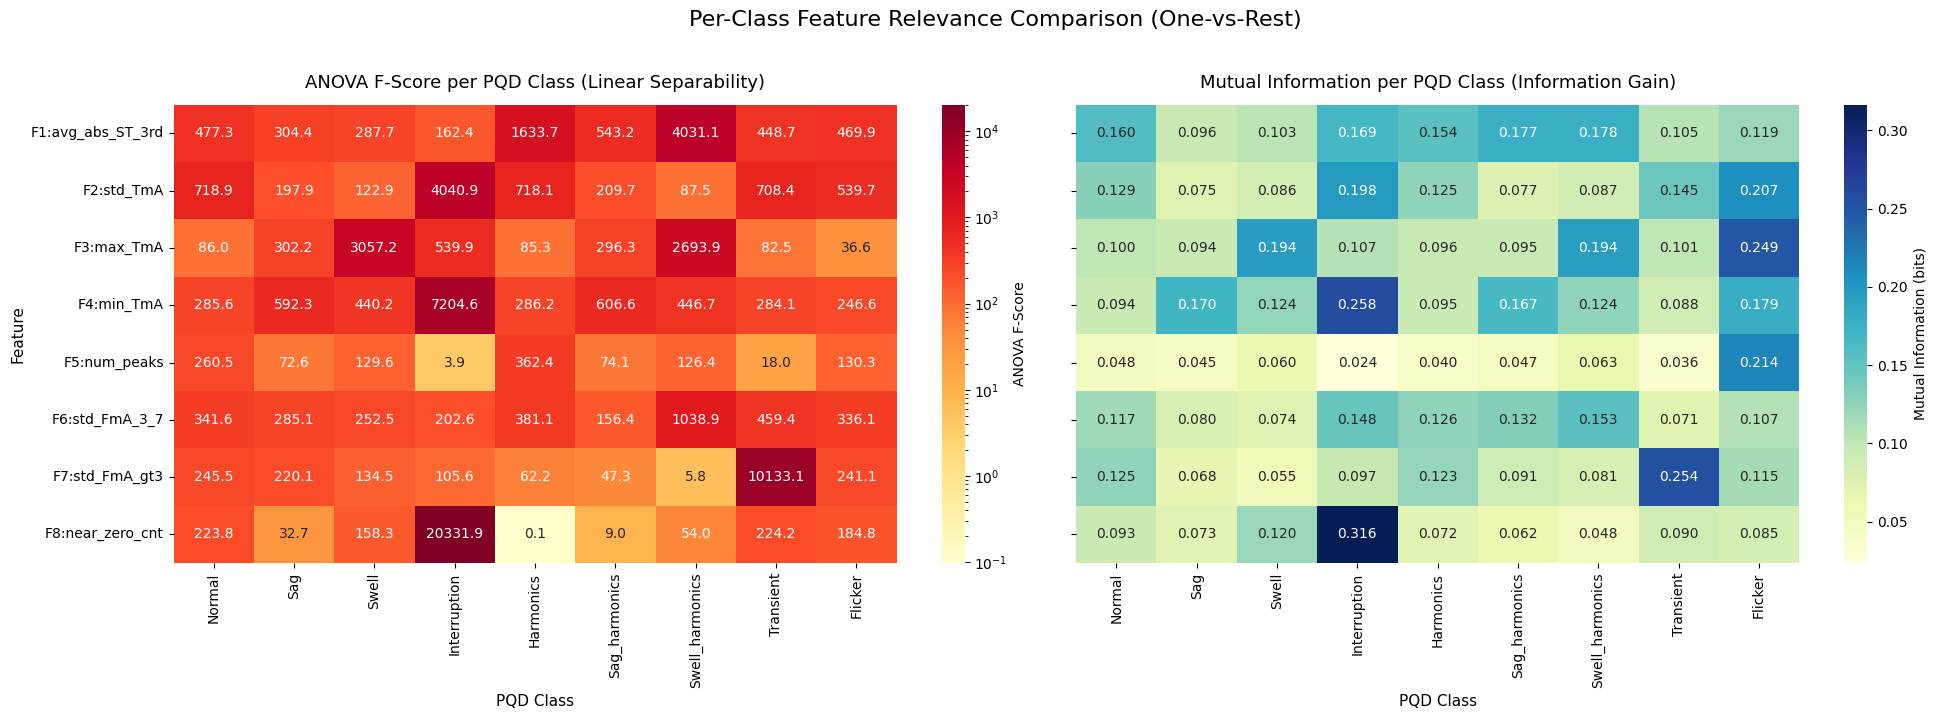

In [4]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import f_classif, mutual_info_classif

from import_folder import PQD_INDICES, import_all_noiselevel_data


# Helper function to print ranked feature relevance per class
def print_ranked_features(
    score_df: pd.DataFrame, metric_name: str, unit: str = ""
):
    """Prints a formatted ranking table of features per PQD class."""
    print(
        f"=== RANKED FEATURE RELEVANCE PER PQD CLASS ({metric_name.upper()}) ===\n"
    )
    for class_name in score_df.columns:
        ranked = score_df[class_name].sort_values(ascending=False)
        print(f"--- PQD Class: {class_name} ---")
        for rank, (feat, score) in enumerate(ranked.items(), start=1):
            print(f"  {rank}. {feat:<20} ({metric_name}: {score:10.4f} {unit})")
        print()


# -----------------------------------------------------------------------------
# 1. Load Data Across All Noise Levels
# -----------------------------------------------------------------------------
folders = ["SNR_noiseless", "SNR_50dB", "SNR_40dB", "SNR_30dB", "SNR_20dB"]

all_data = import_all_noiselevel_data(folders, add_noise_column=False)
X = all_data.drop(columns=["label"])
y = all_data["label"]

# Map numerical target indices back to PQD class names
CLASS_NAMES = {v: k for k, v in PQD_INDICES.items()}
unique_classes = sorted(y.unique())


# -----------------------------------------------------------------------------
# 2. Calculate One-vs-Rest ANOVA F-Scores & Mutual Information Scores
# -----------------------------------------------------------------------------
per_class_f_scores = {}
per_class_mi_scores = {}

for class_idx in unique_classes:
    class_name = CLASS_NAMES[class_idx]

    # Binary classification target: 1 for current PQD class, 0 for rest
    y_binary = (y == class_idx).astype(int)

    # Compute ANOVA F-scores
    f_vals, _ = f_classif(X, y_binary)
    per_class_f_scores[class_name] = f_vals

    # Compute Mutual Information scores
    mi_vals = mutual_info_classif(X, y_binary, random_state=42)
    per_class_mi_scores[class_name] = mi_vals

# Create DataFrames (Rows = Features, Columns = PQD Classes)
f_score_df = pd.DataFrame(per_class_f_scores, index=X.columns)
mi_score_df = pd.DataFrame(per_class_mi_scores, index=X.columns)


# -----------------------------------------------------------------------------
# 3. Print Ranked Tables
# -----------------------------------------------------------------------------
print_ranked_features(f_score_df, metric_name="F-Score")
print_ranked_features(mi_score_df, metric_name="MI Score", unit="bits")


# -----------------------------------------------------------------------------
# 4. Side-by-Side Heatmap Visualization
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(20, 7), sharey=True)

# Panel 1: ANOVA F-Score Heatmap
sns.heatmap(
    f_score_df,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "ANOVA F-Score"},
    ax=axes[0],
    norm=LogNorm(),
)
axes[0].set_title(
    "ANOVA F-Score per PQD Class (Linear Separability)", fontsize=13, pad=12
)
axes[0].set_xlabel("PQD Class", fontsize=11)
axes[0].set_ylabel("Feature", fontsize=11)

# Panel 2: Mutual Information Heatmap
sns.heatmap(
    mi_score_df,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    cbar_kws={"label": "Mutual Information (bits)"},
    ax=axes[1],
)
axes[1].set_title(
    "Mutual Information per PQD Class (Information Gain)", fontsize=13, pad=12
)
axes[1].set_xlabel("PQD Class", fontsize=11)

plt.suptitle(
    "Per-Class Feature Relevance Comparison (One-vs-Rest)",
    fontsize=16,
    y=1.02,
)
plt.tight_layout()
plt.show()